# Lab 04: Feature Selection - Đánh giá hiệu suất
**Môn học:** Học Máy (Machine Learning) - Tuần 04
**Tập dữ liệu:** House Price Prediction (Kaggle)
**Mục tiêu:**
- Tiền xử lý dữ liệu.
- Đánh giá hiệu suất của các kỹ thuật Feature Selection với các mô hình cơ bản: SVM, XGBoost, RandomForest.

In [1]:
# Import các thư viện cơ bản cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore') # Ẩn đi các cảnh báo cho dễ nhìn

# Thư viện cho Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import xgboost as xgb
from sklearn.metrics import mean_squared_error

### Bước 1: Đọc và tiền xử lý dữ liệu

In [2]:
# Đọc dữ liệu tập train
df = pd.read_csv('train.csv')
print("Kích thước dữ liệu gốc:", df.shape)

# Loại bỏ các điểm ngoại lai (Outliers) - Dựa vào phân tích từ Lab 03
# Loại bỏ nhà có diện tích rất lớn (>4000) nhưng giá lại quá rẻ (<300000)
df = df.drop(df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)].index)

# Tách biến Categorical (định tính) và Numerical (định lượng)
cat_cols = df.select_dtypes(include=['object']).columns
num_cols = df.select_dtypes(exclude=['object']).columns

# Xử lý Missing Values đơn giản
# Điền chữ 'None' cho các cột string bị thiếu
df[cat_cols] = df[cat_cols].fillna('None')

# Điền 0 cho biến số bị thiếu (đa số là đo lường diện tích)
for col in num_cols:
    if col != 'LotFrontage':
        df[col] = df[col].fillna(0)

# Riêng mặt tiền (LotFrontage) điền bằng trung vị
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

print("Kiểm tra dữ liệu thiếu sau xử lý:", df.isnull().sum().max())

Kích thước dữ liệu gốc: (1460, 81)
Kiểm tra dữ liệu thiếu sau xử lý: 0


In [3]:
# Mã hóa (Encode) các biến phân loại để mô hình đọc được
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Tách tập Features (X) và Target (y)
X = df.drop(['Id', 'SalePrice'], axis=1)

# Lấy log(1+x) cho SalePrice để phân phối chuẩn hơn (tốt cho dự đoán)
y = np.log1p(df['SalePrice'])

# Chia tập Train - Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa (Scale) dữ liệu (rất cần thiết cho mô hình SVM)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

### Bước 2: Chuẩn bị hàm đánh giá mô hình

In [4]:
# Định nghĩa hàm chạy 3 mô hình cơ bản và tính RMSE
def evaluate_models(X_tr, X_te, y_tr, y_te, feature_set_name=""):
    models = {
        'SVM (SVR)': SVR(),
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
        'XGBoost': xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
    }
    results = {}
    print(f"--- Đánh giá mô hình với {feature_set_name} ---")
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        preds = model.predict(X_te)
        # Tính RMSE
        rmse = np.sqrt(mean_squared_error(y_te, preds))
        results[name] = rmse
        print(f"{name}: RMSE = {rmse:.4f}")
    print("\n")
    return results

### Bước 3: Đánh giá hiệu suất với các kỹ thuật Feature Selection

In [5]:
# 1. Base Model (Dùng tất cả đặc trưng - Không dùng Feature Selection)
print("Số lượng features gốc:", X_train_scaled.shape[1])
res_base = evaluate_models(X_train_scaled, X_test_scaled, y_train, y_test, "Tất cả Features (Baseline)")

Số lượng features gốc: 79
--- Đánh giá mô hình với Tất cả Features (Baseline) ---


SVM (SVR): RMSE = 0.1767


Random Forest: RMSE = 0.1424


XGBoost: RMSE = 0.1420




In [6]:
# 2. Kỹ thuật Filter Method: Dùng SelectKBest
# Chọn ra top 30 features có mức độ quan hệ tuyến tính cao nhất với Target
selector_kbest = SelectKBest(score_func=f_regression, k=30)
X_train_kbest = selector_kbest.fit_transform(X_train_scaled, y_train)
X_test_kbest = selector_kbest.transform(X_test_scaled)

kbest_features = X.columns[selector_kbest.get_support()]
print("Top 30 features (SelectKBest):", list(kbest_features))

res_kbest = evaluate_models(X_train_kbest, X_test_kbest, y_train, y_test, "SelectKBest (Top 30)")

Top 30 features (SelectKBest): ['LotFrontage', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual', 'Foundation', 'BsmtQual', 'BsmtExposure', 'BsmtFinSF1', 'TotalBsmtSF', 'HeatingQC', 'CentralAir', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'FullBath', 'HalfBath', 'KitchenQual', 'TotRmsAbvGrd', 'Fireplaces', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF']
--- Đánh giá mô hình với SelectKBest (Top 30) ---
SVM (SVR): RMSE = 0.1556


Random Forest: RMSE = 0.1515


XGBoost: RMSE = 0.1587




In [7]:
# 3. Kỹ thuật Embedded Method: Dùng Random Forest Feature Importance
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)

# Tính độ quan trọng của các features
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
# Lấy top 30 features quan trọng nhất
top_rf_features = importances.nlargest(30).index
print("Top 30 features (Random Forest Importance):", list(top_rf_features))

X_train_rf = X_train_scaled[top_rf_features]
X_test_rf = X_test_scaled[top_rf_features]

res_rf = evaluate_models(X_train_rf, X_test_rf, y_train, y_test, "RF Importance (Top 30)")

Top 30 features (Random Forest Importance): ['OverallQual', 'GrLivArea', 'GarageArea', 'TotalBsmtSF', 'GarageCars', 'BsmtFinSF1', '1stFlrSF', 'GarageType', 'CentralAir', 'LotArea', 'YearBuilt', 'OverallCond', 'YearRemodAdd', 'GarageYrBlt', 'BsmtQual', 'BsmtUnfSF', 'Neighborhood', '2ndFlrSF', 'OpenPorchSF', 'TotRmsAbvGrd', 'LotFrontage', 'Fireplaces', 'MSZoning', 'KitchenQual', 'MasVnrArea', 'WoodDeckSF', 'MoSold', 'GarageFinish', 'BsmtFinType1', 'MSSubClass']
--- Đánh giá mô hình với RF Importance (Top 30) ---
SVM (SVR): RMSE = 0.1510


Random Forest: RMSE = 0.1417


XGBoost: RMSE = 0.1354




### Bước 4: Tổng hợp và So sánh kết quả

,Base (All Features),SelectKBest (Top 30),RF Importance (Top 30)
SVM (SVR),0.176718,0.155558,0.150953
Random Forest,0.142414,0.151474,0.141652
XGBoost,0.141967,0.158718,0.135414


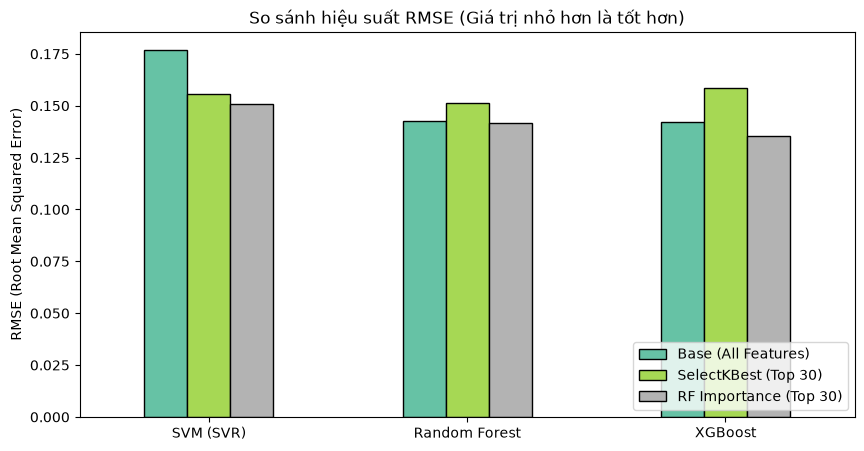

In [8]:
# Bảng tổng hợp so sánh RMSE (Càng nhỏ càng tốt)
summary_df = pd.DataFrame({
    'Base (All Features)': res_base,
    'SelectKBest (Top 30)': res_kbest,
    'RF Importance (Top 30)': res_rf
})

display(summary_df)

# Vẽ biểu đồ trực quan
summary_df.plot(kind='bar', figsize=(10, 5), colormap='Set2', edgecolor='black')
plt.title('So sánh hiệu suất RMSE (Giá trị nhỏ hơn là tốt hơn)')
plt.ylabel('RMSE (Root Mean Squared Error)')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()